<a href="https://colab.research.google.com/github/Ahmettufan3310/74-musteri-segmentasyonu-rfm/blob/main/notebooks/04_alternatif_kumeleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/Ahmettufan3310/74-musteri-segmentasyonu-rfm/main/data/rfm_olcekli.csv"
rfm = pd.read_csv(url)
X = rfm[['Recency', 'Frequency', 'Monetary']]
print(rfm.shape)

(4333, 5)


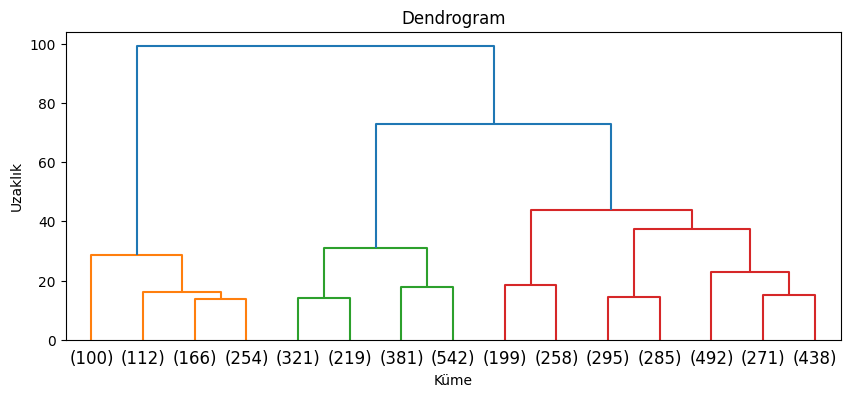

In [2]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

baglanti = linkage(X, method='ward')   # birleştirme ağacı

plt.figure(figsize=(10, 4))
dendrogram(baglanti, truncate_mode='lastp', p=15)
plt.title('Dendrogram')
plt.xlabel('Küme')
plt.ylabel('Uzaklık')
plt.show()

In [3]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

hiyerarsik = AgglomerativeClustering(n_clusters=4, linkage='ward')
etiket_h = hiyerarsik.fit_predict(X)

sil_h = round(silhouette_score(X, etiket_h), 3)
db_h = round(davies_bouldin_score(X, etiket_h), 3)
print("Küme büyüklükleri:", pd.Series(etiket_h).value_counts().sort_index().tolist())
print("Silhouette:", sil_h, "| Davies-Bouldin:", db_h)

Küme büyüklükleri: [1781, 632, 1463, 457]
Silhouette: 0.291 | Davies-Bouldin: 1.036


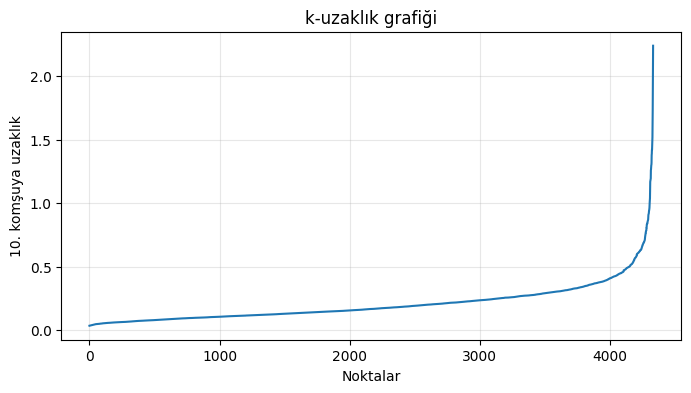

In [4]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

komsu = NearestNeighbors(n_neighbors=10).fit(X)
uzakliklar, _ = komsu.kneighbors(X)
uzakliklar = np.sort(uzakliklar[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(uzakliklar)
plt.title('k-uzaklık grafiği')
plt.xlabel('Noktalar')
plt.ylabel('10. komşuya uzaklık')
plt.grid(alpha=.3)
plt.show()

In [5]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.5, min_samples=10)
etiket_d = db.fit_predict(X)

gurultu = (etiket_d == -1).sum()
kume_sayisi_d = len(set(etiket_d)) - (1 if -1 in etiket_d else 0)
print("Küme sayısı:", kume_sayisi_d)
print("Gürültü:", gurultu, f"(%{gurultu/len(X)*100:.1f})")
print("Dağılım:", pd.Series(etiket_d).value_counts().sort_index().to_dict())

mask = etiket_d != -1
if len(set(etiket_d[mask])) >= 2:
    sil_d = round(silhouette_score(X[mask], etiket_d[mask]), 3)
    db_d = round(davies_bouldin_score(X[mask], etiket_d[mask]), 3)
    print("Silhouette:", sil_d, "| Davies-Bouldin:", db_d)
else:
    sil_d, db_d = "hesaplanamadı", "hesaplanamadı"
    print("Yeterli küme oluşmadı")

Küme sayısı: 2
Gürültü: 75 (%1.7)
Dağılım: {-1: 75, 0: 2766, 1: 1492}
Silhouette: 0.296 | Davies-Bouldin: 1.062


In [6]:
karsilastirma = pd.DataFrame({
    'Algoritma': ['K-Means', 'Hiyerarşik', 'DBSCAN'],
    'Küme Sayısı': [4, 4, kume_sayisi_d],
    'Silhouette': [0.337, sil_h, sil_d],
    'Davies-Bouldin': [1.012, db_h, db_d],
})
print(karsilastirma.to_string(index=False))

 Algoritma  Küme Sayısı  Silhouette  Davies-Bouldin
   K-Means            4       0.337           1.012
Hiyerarşik            4       0.291           1.036
    DBSCAN            2       0.296           1.062
